In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.metrics import classification_report, confusion_matrix, ConfusionMatrixDisplay
from sklearn.preprocessing import LabelEncoder

plt.style.use('seaborn-v0_8')
sns.set_palette('Set2')

In [ ]:
# ====================== 1. ЗАГРУЗКА ДАТАСЕТА ======================
df = pd.read_csv('Loan_default.csv')   # ←←← УКАЖИ СВОЙ ПУТЬ К ФАЙЛУ

print("✅ Размер датасета:", df.shape)
print("Колонки:", df.columns.tolist())

# Авто-определение target
target_col = None
for col in df.columns:
    if col.lower() in ['default', 'loan_status', 'status', 'risk', 'target', 'defaulted']:
        target_col = col
        break
if target_col is None:
    target_col = df.columns[-1]

print(f"Целевая переменная: {target_col}")
print("\nБаланс классов:\n", df[target_col].value_counts(normalize=True))

✅ Размер датасета: (255347, 18)
Колонки: ['LoanID', 'Age', 'Income', 'LoanAmount', 'CreditScore', 'MonthsEmployed', 'NumCreditLines', 'InterestRate', 'LoanTerm', 'DTIRatio', 'Education', 'EmploymentType', 'MaritalStatus', 'HasMortgage', 'HasDependents', 'LoanPurpose', 'HasCoSigner', 'Default']
🎯 Целевая переменная: Default

Баланс классов:
 Default
0    0.883872
1    0.116128
Name: proportion, dtype: float64



📋 Информация о датасете:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 255347 entries, 0 to 255346
Data columns (total 18 columns):
 #   Column          Non-Null Count   Dtype  
---  ------          --------------   -----  
 0   LoanID          255347 non-null  object 
 1   Age             255347 non-null  int64  
 2   Income          255347 non-null  int64  
 3   LoanAmount      255347 non-null  int64  
 4   CreditScore     255347 non-null  int64  
 5   MonthsEmployed  255347 non-null  int64  
 6   NumCreditLines  255347 non-null  int64  
 7   InterestRate    255347 non-null  float64
 8   LoanTerm        255347 non-null  int64  
 9   DTIRatio        255347 non-null  float64
 10  Education       255347 non-null  object 
 11  EmploymentType  255347 non-null  object 
 12  MaritalStatus   255347 non-null  object 
 13  HasMortgage     255347 non-null  object 
 14  HasDependents   255347 non-null  object 
 15  LoanPurpose     255347 non-null  object 
 16  HasCoSigner     255347 non-nul

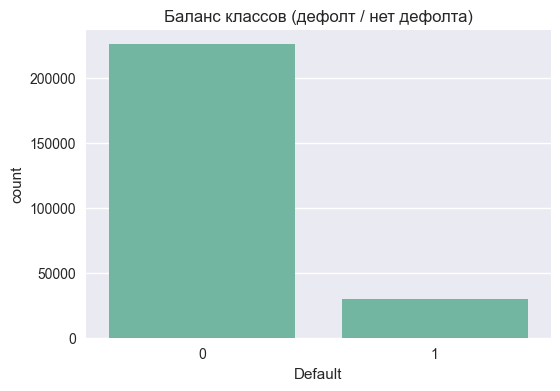

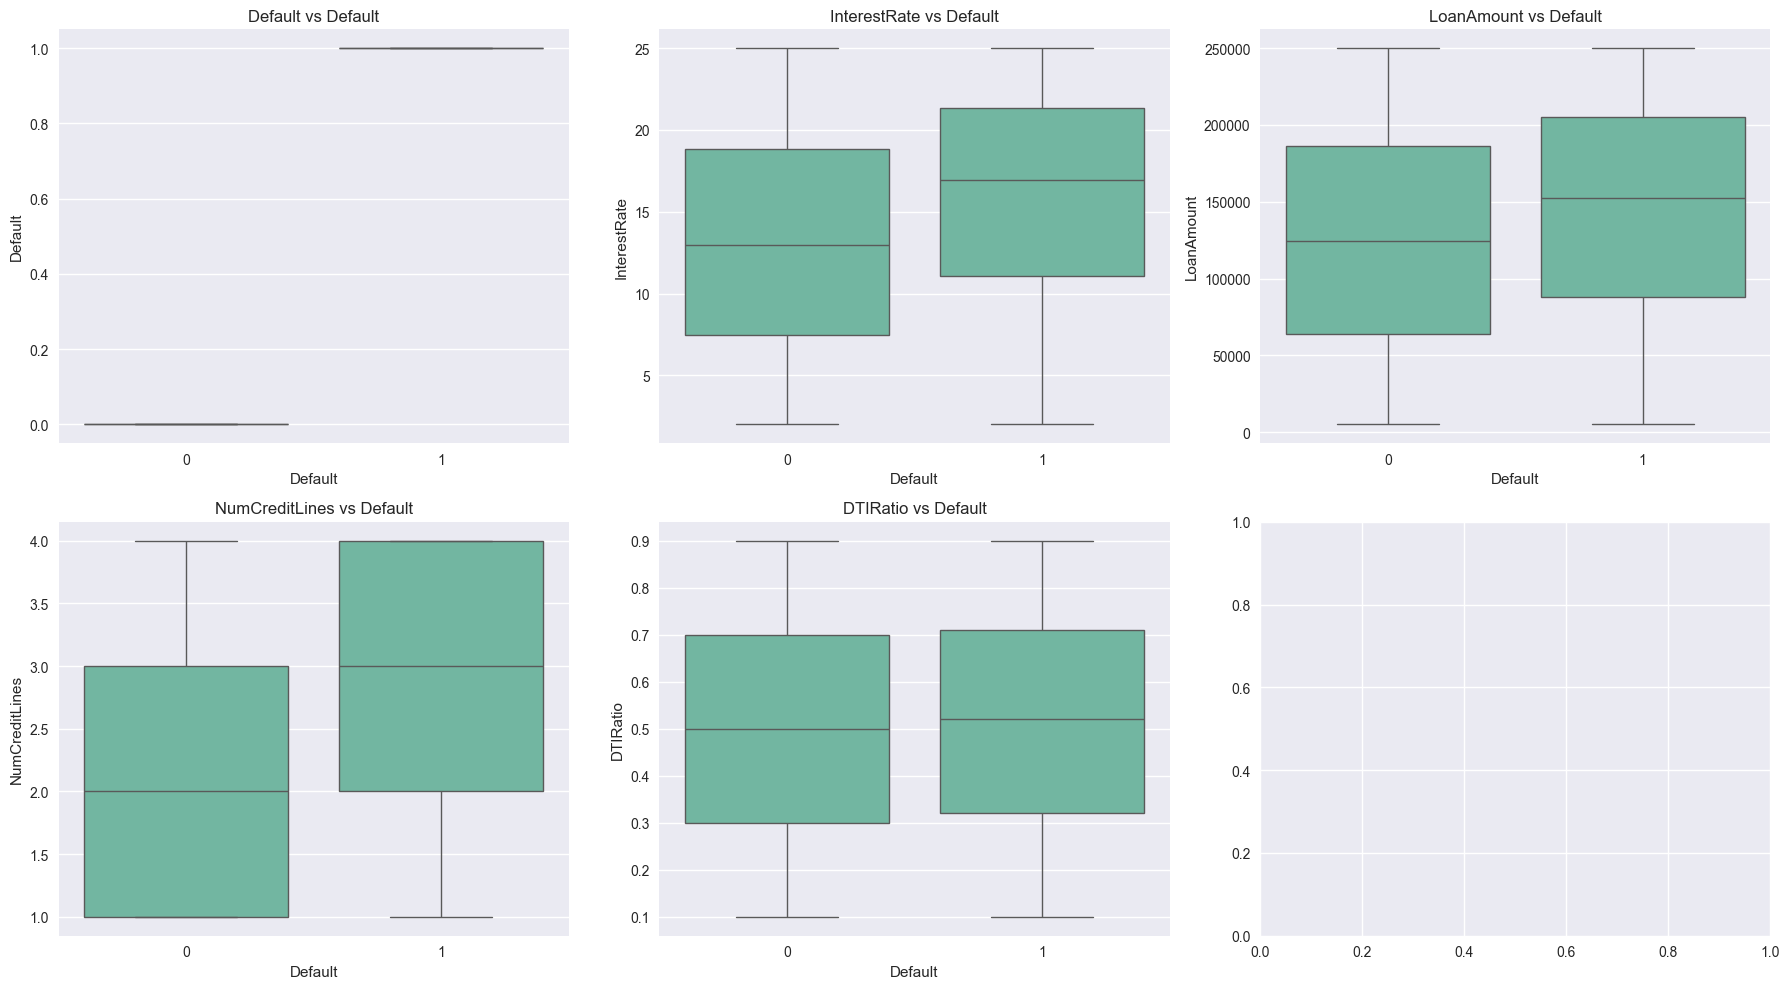

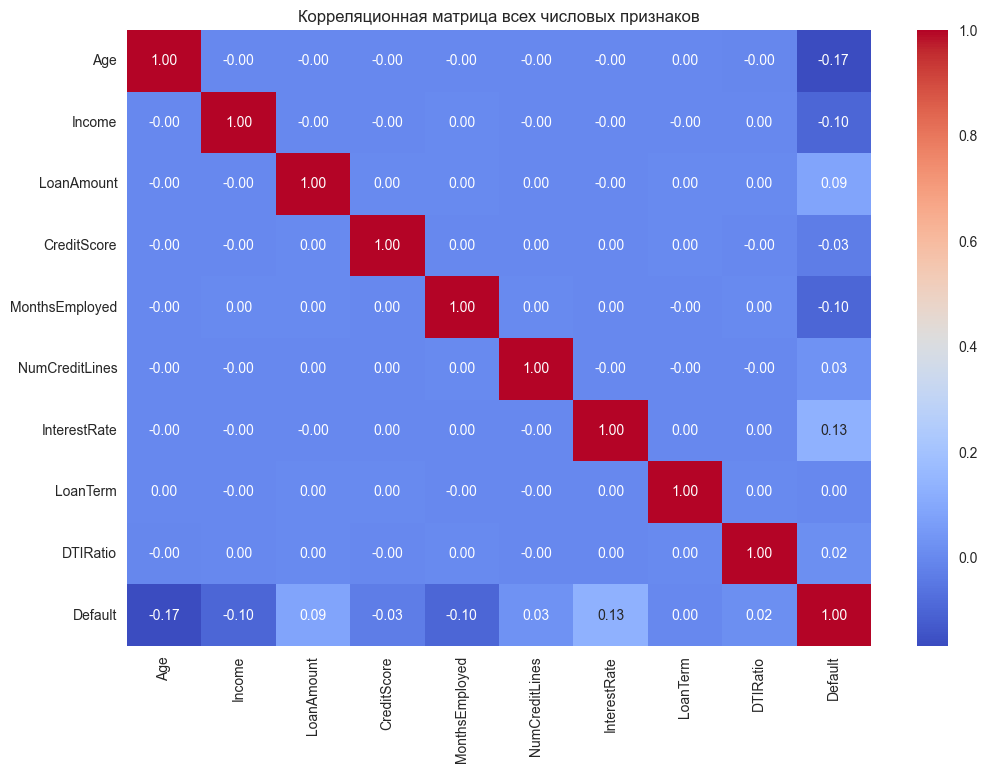

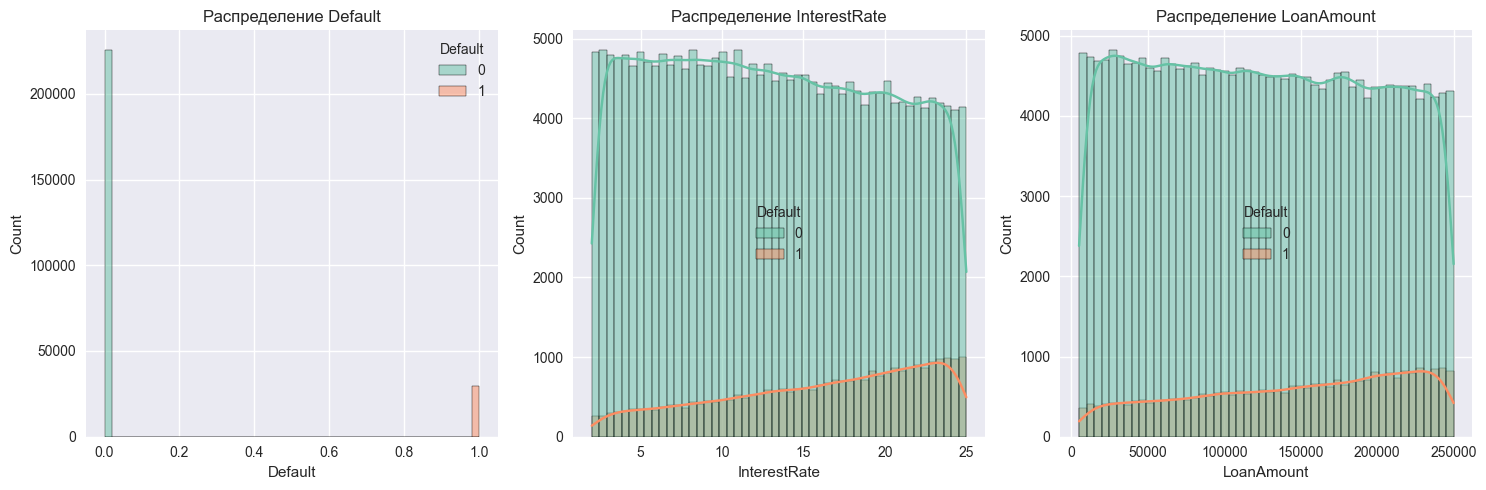

In [ ]:
# ====================== 2. РАСШИРЕННАЯ EDA (ТАБЛИЦЫ + ВИЗУАЛИЗАЦИЯ) ======================

# Таблица 1: Общая информация
print("\n Информация о датасете:")
print(df.info())

# Таблица 2: Статистика числовых признаков
print("\n Описательная статистика:")
print(df.describe().round(2))

# Таблица 3: Корреляция с target
numeric_cols = df.select_dtypes(include=np.number).columns.tolist()
if target_col in numeric_cols:
    numeric_cols.remove(target_col)

corr = df[numeric_cols + [target_col]].corr()[target_col].sort_values(ascending=False)
print("\n🔥 Корреляция признаков с target (по убыванию):")
print(corr.round(3))

# Визуализация 1: Баланс классов
plt.figure(figsize=(6,4))
sns.countplot(data=df, x=target_col)
plt.title('Баланс классов (дефолт / нет дефолта)')
plt.show()

# Визуализация 2–5: Boxplot по самым важным признакам (авто-выбор)
top_features = corr.index[:5].tolist()  # топ-5 по корреляции
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
for i, feat in enumerate(top_features[:6]):
    row, col = divmod(i, 3)
    if feat in df.columns:
        sns.boxplot(data=df, x=target_col, y=feat, ax=axes[row, col])
        axes[row, col].set_title(f'{feat} vs {target_col}')
plt.tight_layout()
plt.show()

# Визуализация 6: Корреляционная тепловая карта
plt.figure(figsize=(12, 8))
sns.heatmap(df[numeric_cols + [target_col]].corr(), annot=True, cmap='coolwarm', fmt='.2f')
plt.title('Корреляционная матрица всех числовых признаков')
plt.show()

# Визуализация 7: Распределение топ-3 признаков (гистограммы)
plt.figure(figsize=(15, 5))
for i, feat in enumerate(top_features[:3], 1):
    plt.subplot(1, 3, i)
    sns.histplot(data=df, x=feat, hue=target_col, kde=True, bins=50)
    plt.title(f'Распределение {feat}')
plt.tight_layout()
plt.show()

In [ ]:
# Подготовка данных (числовые + закодированные категориальные)
X = df[numeric_cols].copy()
cat_cols = df.select_dtypes(include='object').columns
for col in cat_cols:
    if col != target_col:
        le = LabelEncoder()
        X[col] = le.fit_transform(df[col].astype(str))

y = df[target_col]

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.3, random_state=42, stratify=y)

# ====================== МОДЕЛЬ 1: GINI ======================
clf_gini = DecisionTreeClassifier(criterion='gini', max_depth=5, random_state=42)
clf_gini.fit(X_train, y_train)
y_pred_gini = clf_gini.predict(X_test)

# ====================== МОДЕЛЬ 2: ENTROPY ======================
clf_entropy = DecisionTreeClassifier(criterion='entropy', max_depth=5, random_state=42)
clf_entropy.fit(X_train, y_train)
y_pred_entropy = clf_entropy.predict(X_test)

# ====================== СРАВНЕНИЕ МОДЕЛЕЙ (ТАБЛИЦА) ======================
print("\n" + "="*60)
print(" СРАВНЕНИЕ МОДЕЛЕЙ: GINI vs ENTROPY")
print("="*60)
print("\n=== Gini ===")
print(classification_report(y_test, y_pred_gini))
print("\n=== Entropy ===")
print(classification_report(y_test, y_pred_entropy))


📊 СРАВНЕНИЕ МОДЕЛЕЙ: GINI vs ENTROPY

=== Gini ===
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     67709
           1       0.58      0.03      0.06      8896

    accuracy                           0.88     76605
   macro avg       0.73      0.52      0.50     76605
weighted avg       0.85      0.88      0.84     76605


=== Entropy ===
              precision    recall  f1-score   support

           0       0.89      1.00      0.94     67709
           1       0.64      0.02      0.04      8896

    accuracy                           0.89     76605
   macro avg       0.76      0.51      0.49     76605
weighted avg       0.86      0.89      0.83     76605



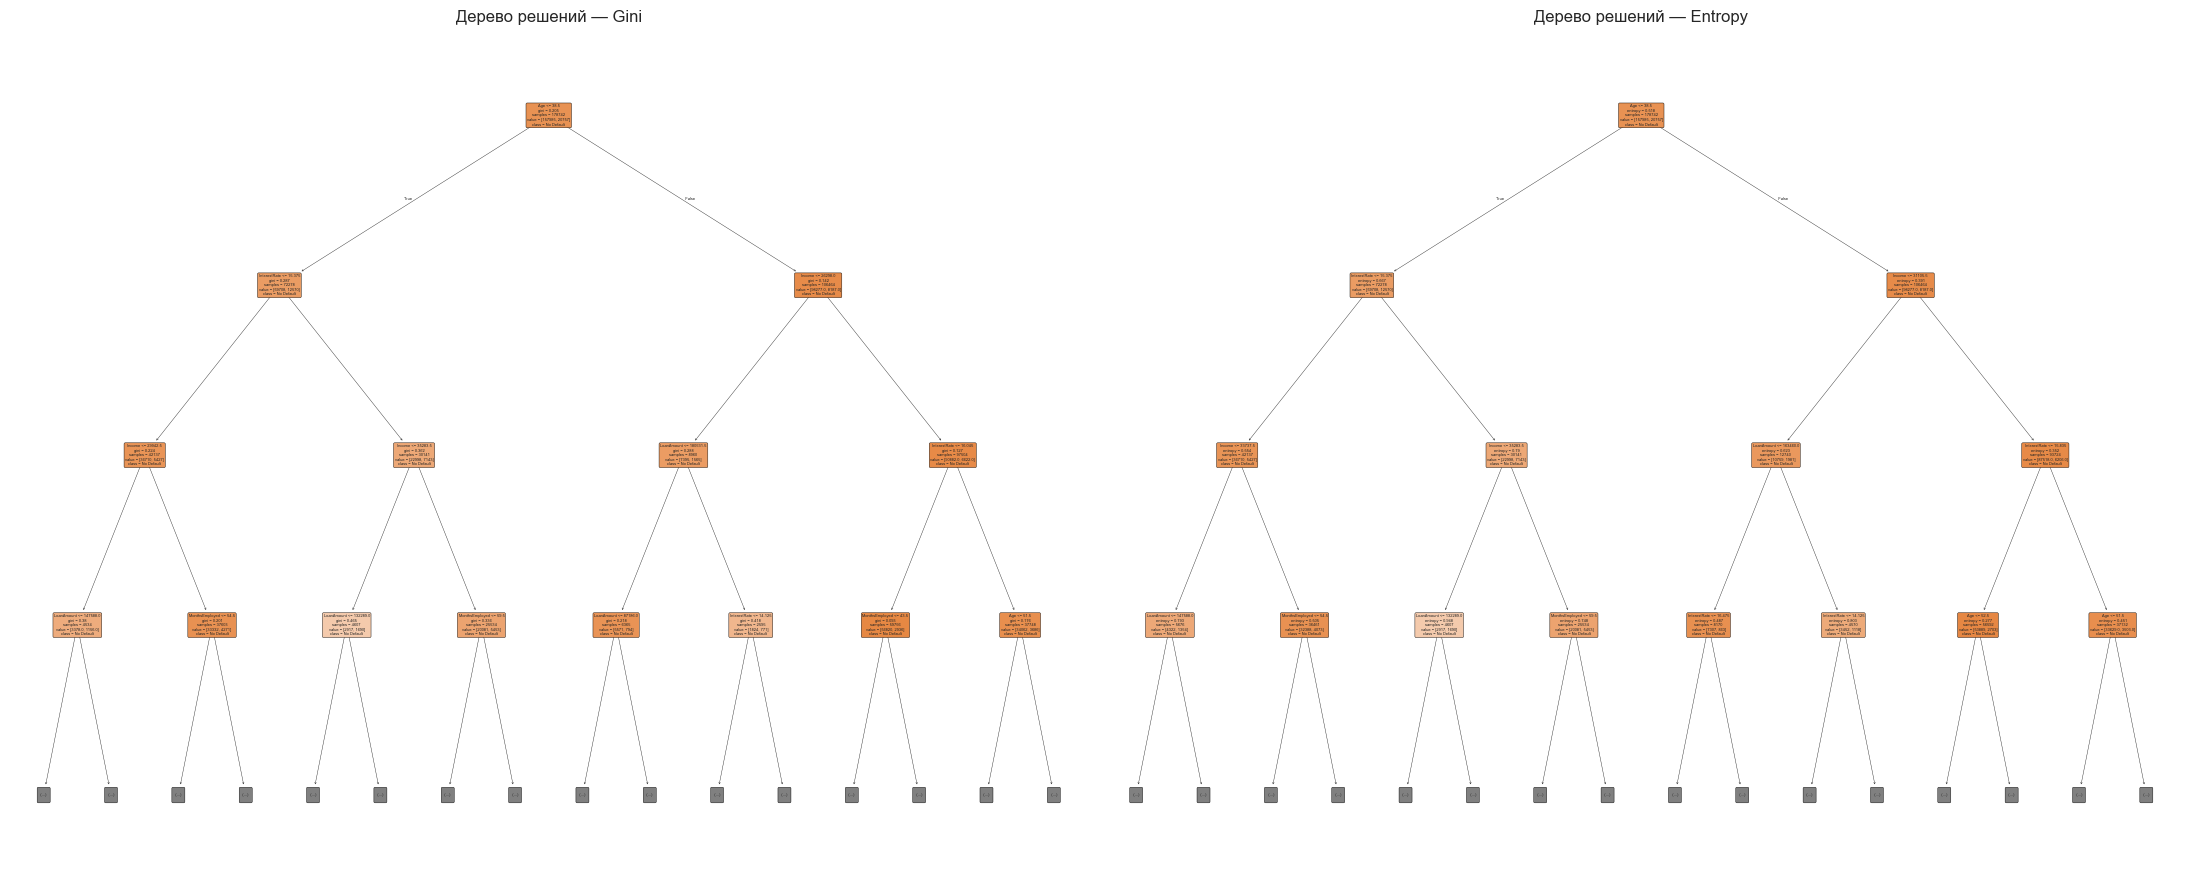

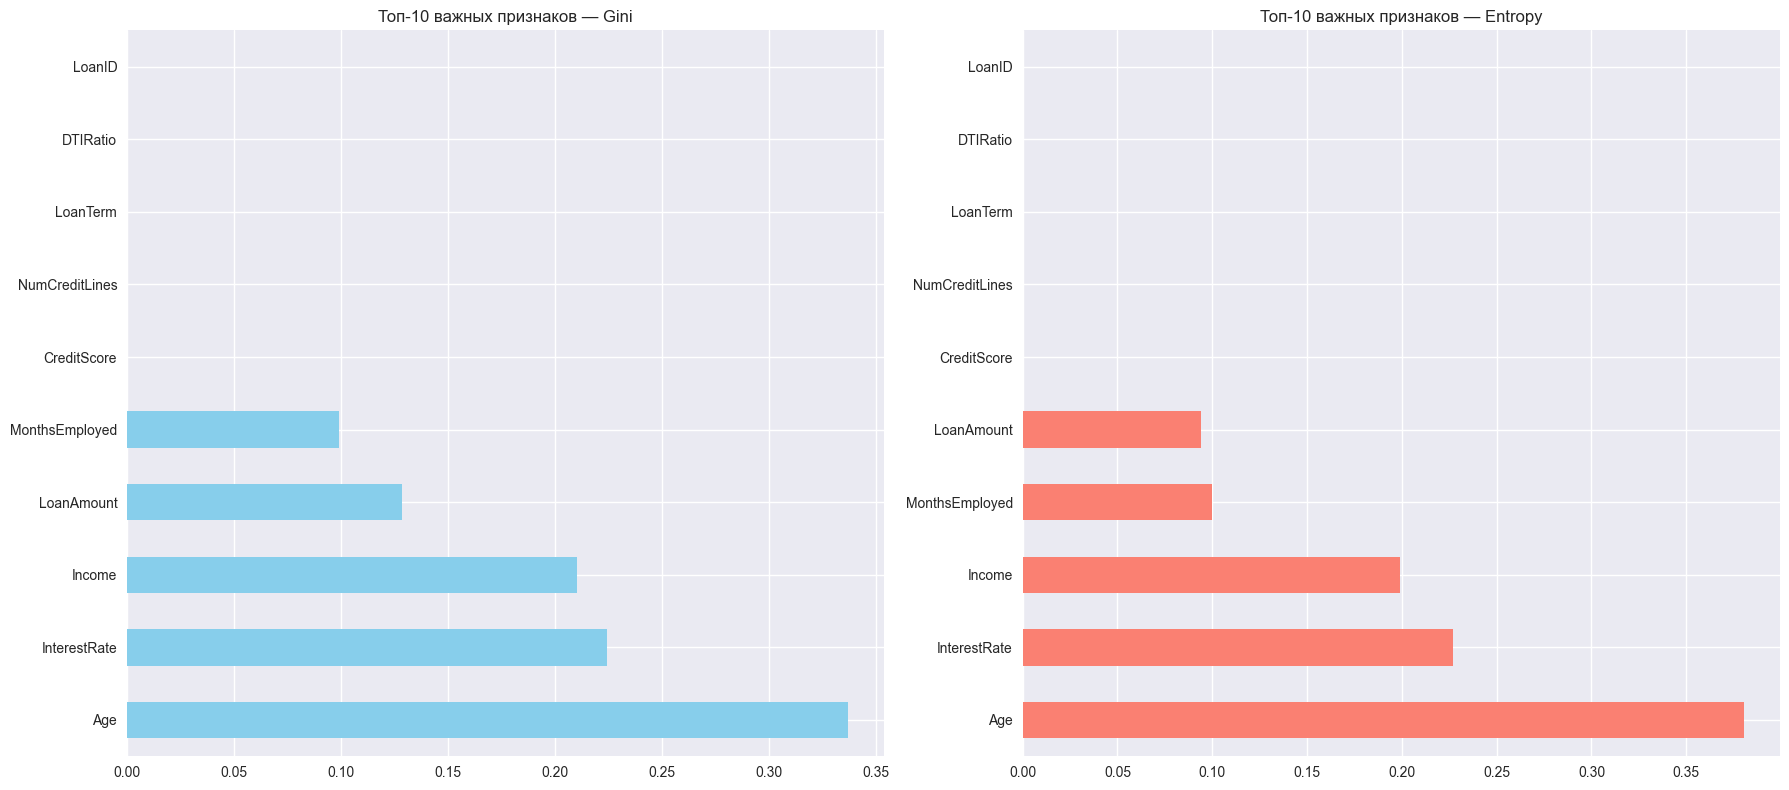


🔥 ТОП-15 самых влиятельных признаков:
           Feature  Gini_Importance  Entropy_Importance
0              Age           0.3372              0.3804
6     InterestRate           0.2244              0.2269
1           Income           0.2105              0.1988
2       LoanAmount           0.1286              0.0940
4   MonthsEmployed           0.0992              0.0999
3      CreditScore           0.0000              0.0000
5   NumCreditLines           0.0000              0.0000
7         LoanTerm           0.0000              0.0000
8         DTIRatio           0.0000              0.0000
9           LoanID           0.0000              0.0000
10       Education           0.0000              0.0000
11  EmploymentType           0.0000              0.0000
12   MaritalStatus           0.0000              0.0000
13     HasMortgage           0.0000              0.0000
14   HasDependents           0.0000              0.0000


In [6]:
# Визуализация деревьев (первые 3 уровня)
fig, axes = plt.subplots(1, 2, figsize=(22, 9))
plot_tree(clf_gini, feature_names=X.columns, class_names=['No Default', 'Default'],
          filled=True, rounded=True, max_depth=3, ax=axes[0])
axes[0].set_title('Дерево решений — Gini')

plot_tree(clf_entropy, feature_names=X.columns, class_names=['No Default', 'Default'],
          filled=True, rounded=True, max_depth=3, ax=axes[1])
axes[1].set_title('Дерево решений — Entropy')
plt.tight_layout()
plt.show()

# Feature Importance — сравнение
imp_gini = pd.Series(clf_gini.feature_importances_, index=X.columns).sort_values(ascending=False)
imp_entropy = pd.Series(clf_entropy.feature_importances_, index=X.columns).sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(18, 8))
imp_gini.head(10).plot(kind='barh', ax=axes[0], color='skyblue')
axes[0].set_title('Топ-10 важных признаков — Gini')
imp_entropy.head(10).plot(kind='barh', ax=axes[1], color='salmon')
axes[1].set_title('Топ-10 важных признаков — Entropy')
plt.tight_layout()
plt.show()

# Общая таблица важности
importance_df = pd.DataFrame({
    'Feature': X.columns,
    'Gini_Importance': clf_gini.feature_importances_,
    'Entropy_Importance': clf_entropy.feature_importances_
}).sort_values('Gini_Importance', ascending=False)
print("\n🔥 ТОП-15 самых влиятельных признаков:")
print(importance_df.head(15).round(4))


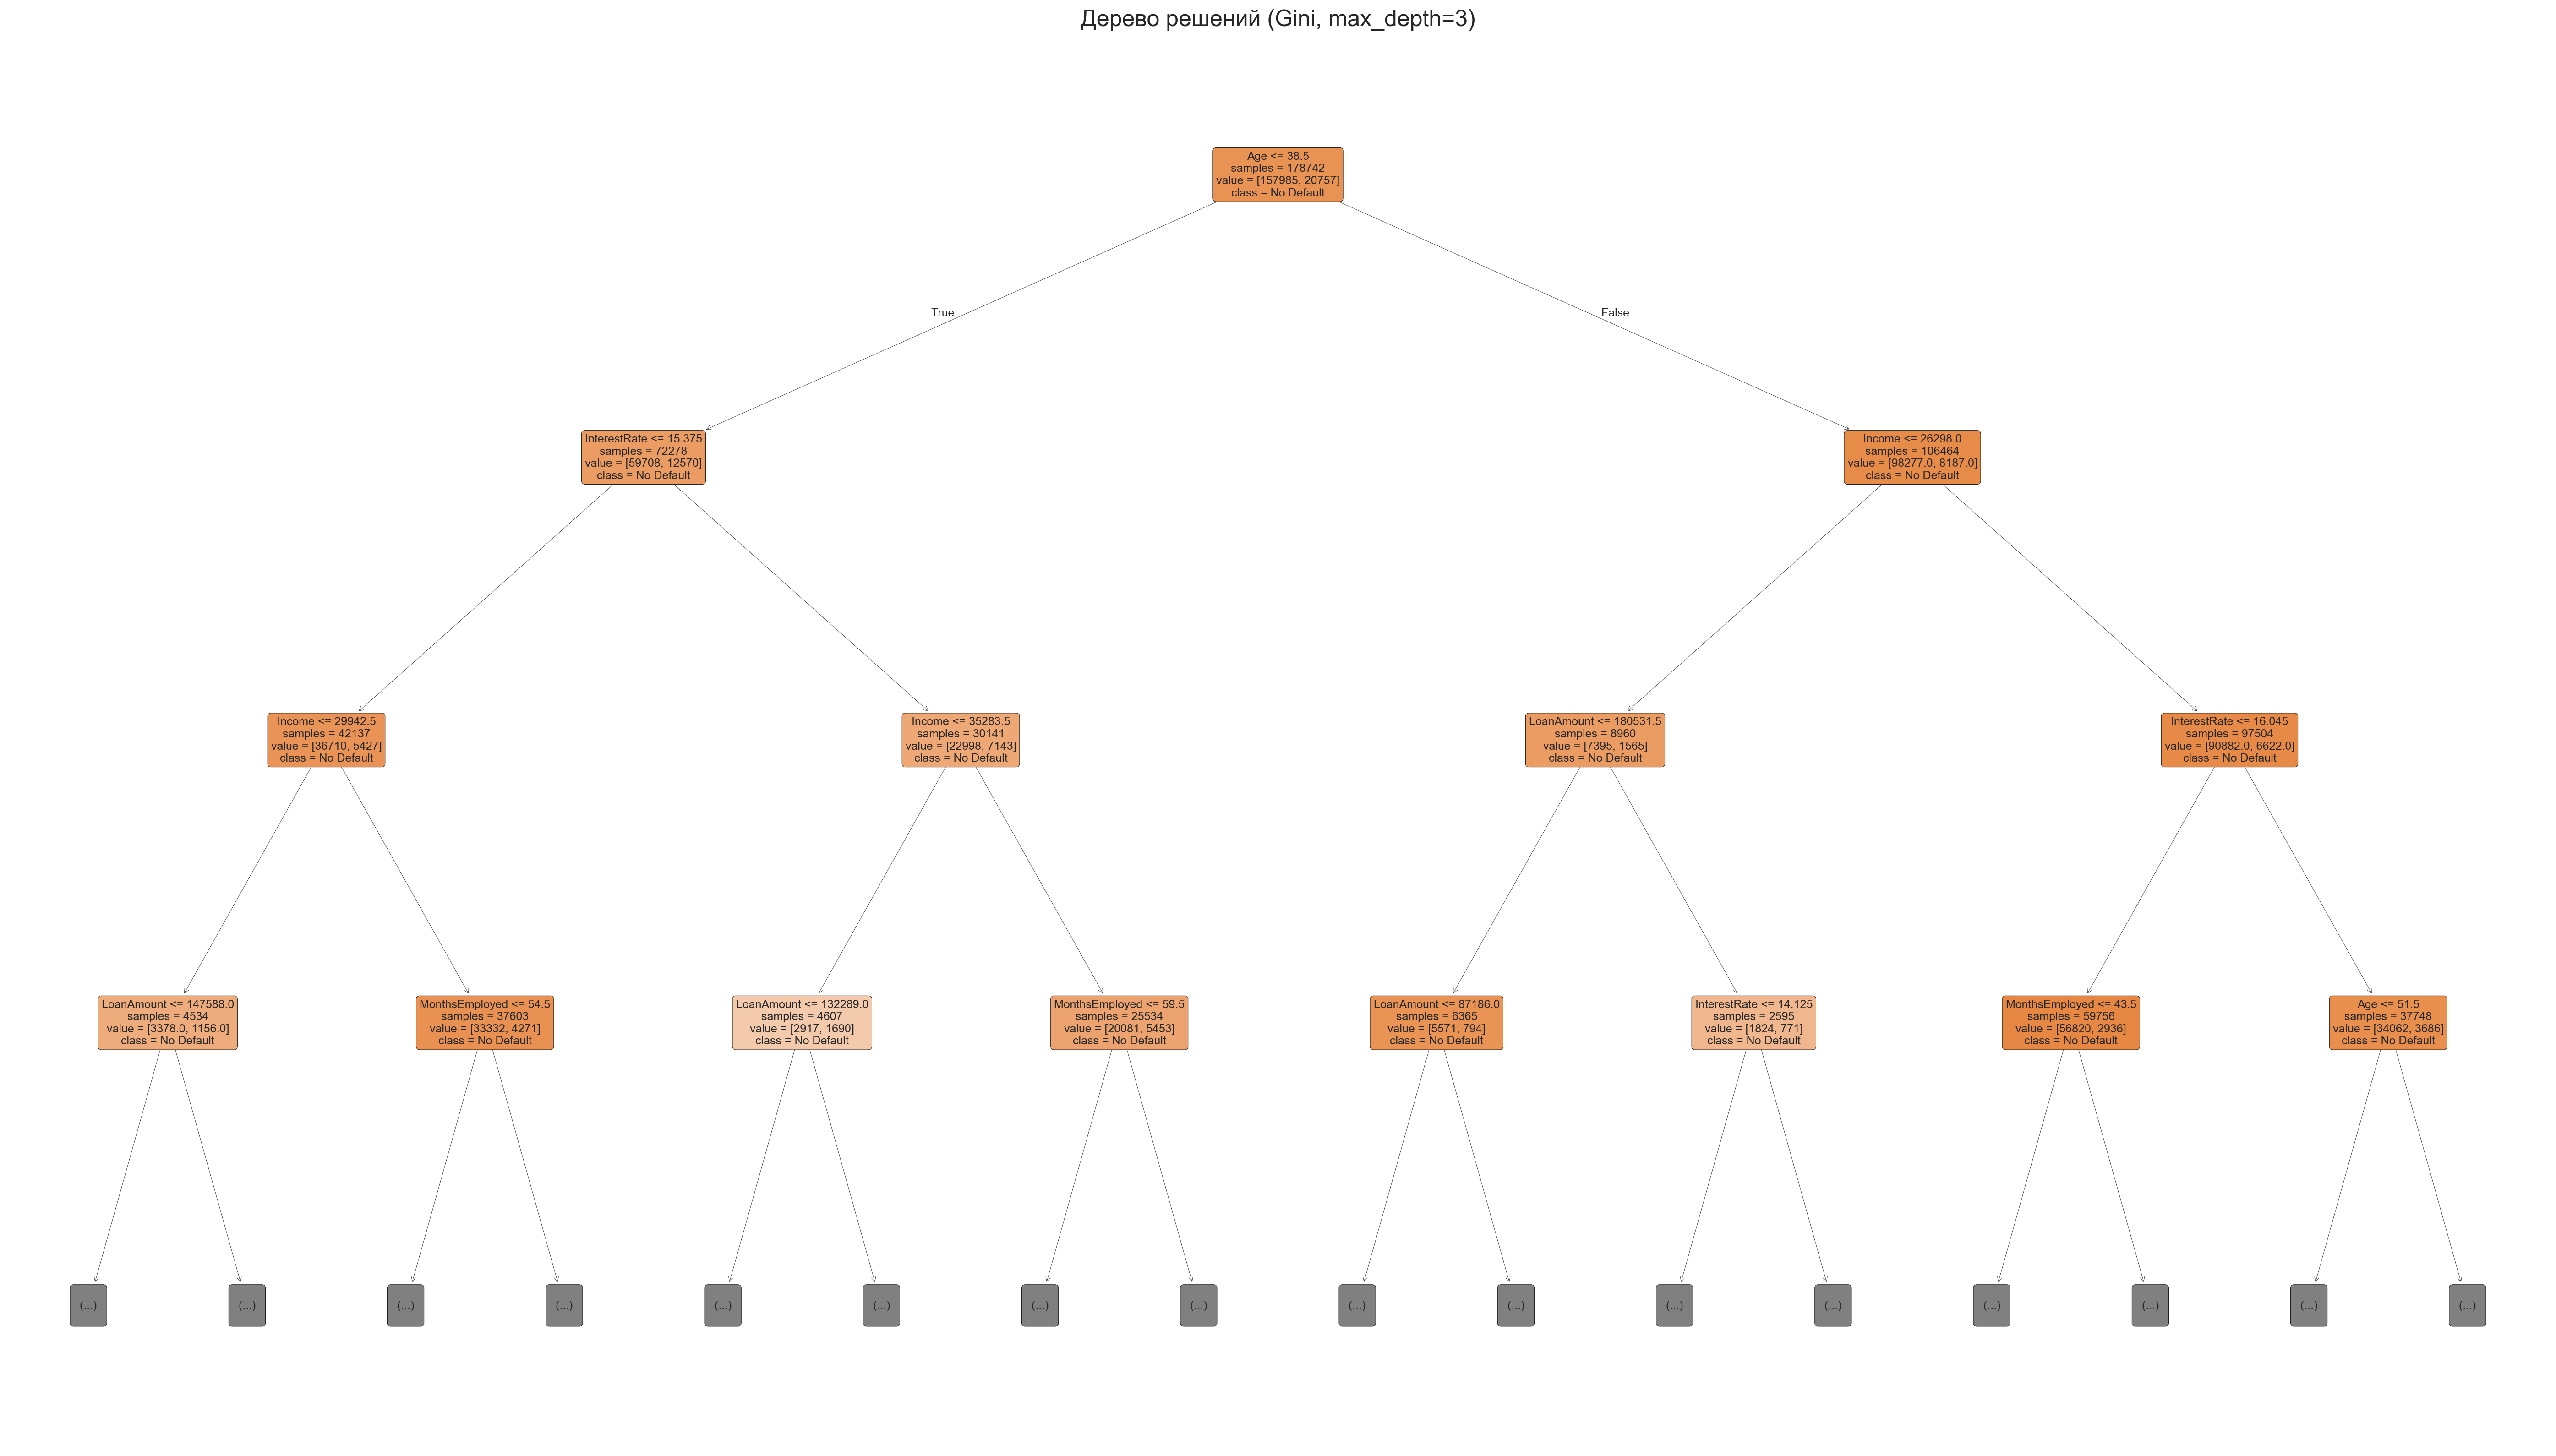

In [10]:
fig = plt.figure(figsize=(28, 16), dpi=200)
_ = plot_tree(clf_gini, 
              feature_names=X.columns.tolist(),
              class_names=['No Default', 'Default'],
              filled=True,
              rounded=True,
              fontsize=9,
              max_depth=3,           # Показываем только первые 3 уровня — очень читаемо
              impurity=False)        # Можно убрать impurity, чтобы было меньше текста

plt.title('Дерево решений (Gini, max_depth=3)', fontsize=18)
plt.tight_layout()
plt.savefig('tree_gini_clear.png', dpi=400, bbox_inches='tight')
plt.savefig('tree_gini_clear.pdf', bbox_inches='tight')
plt.show()

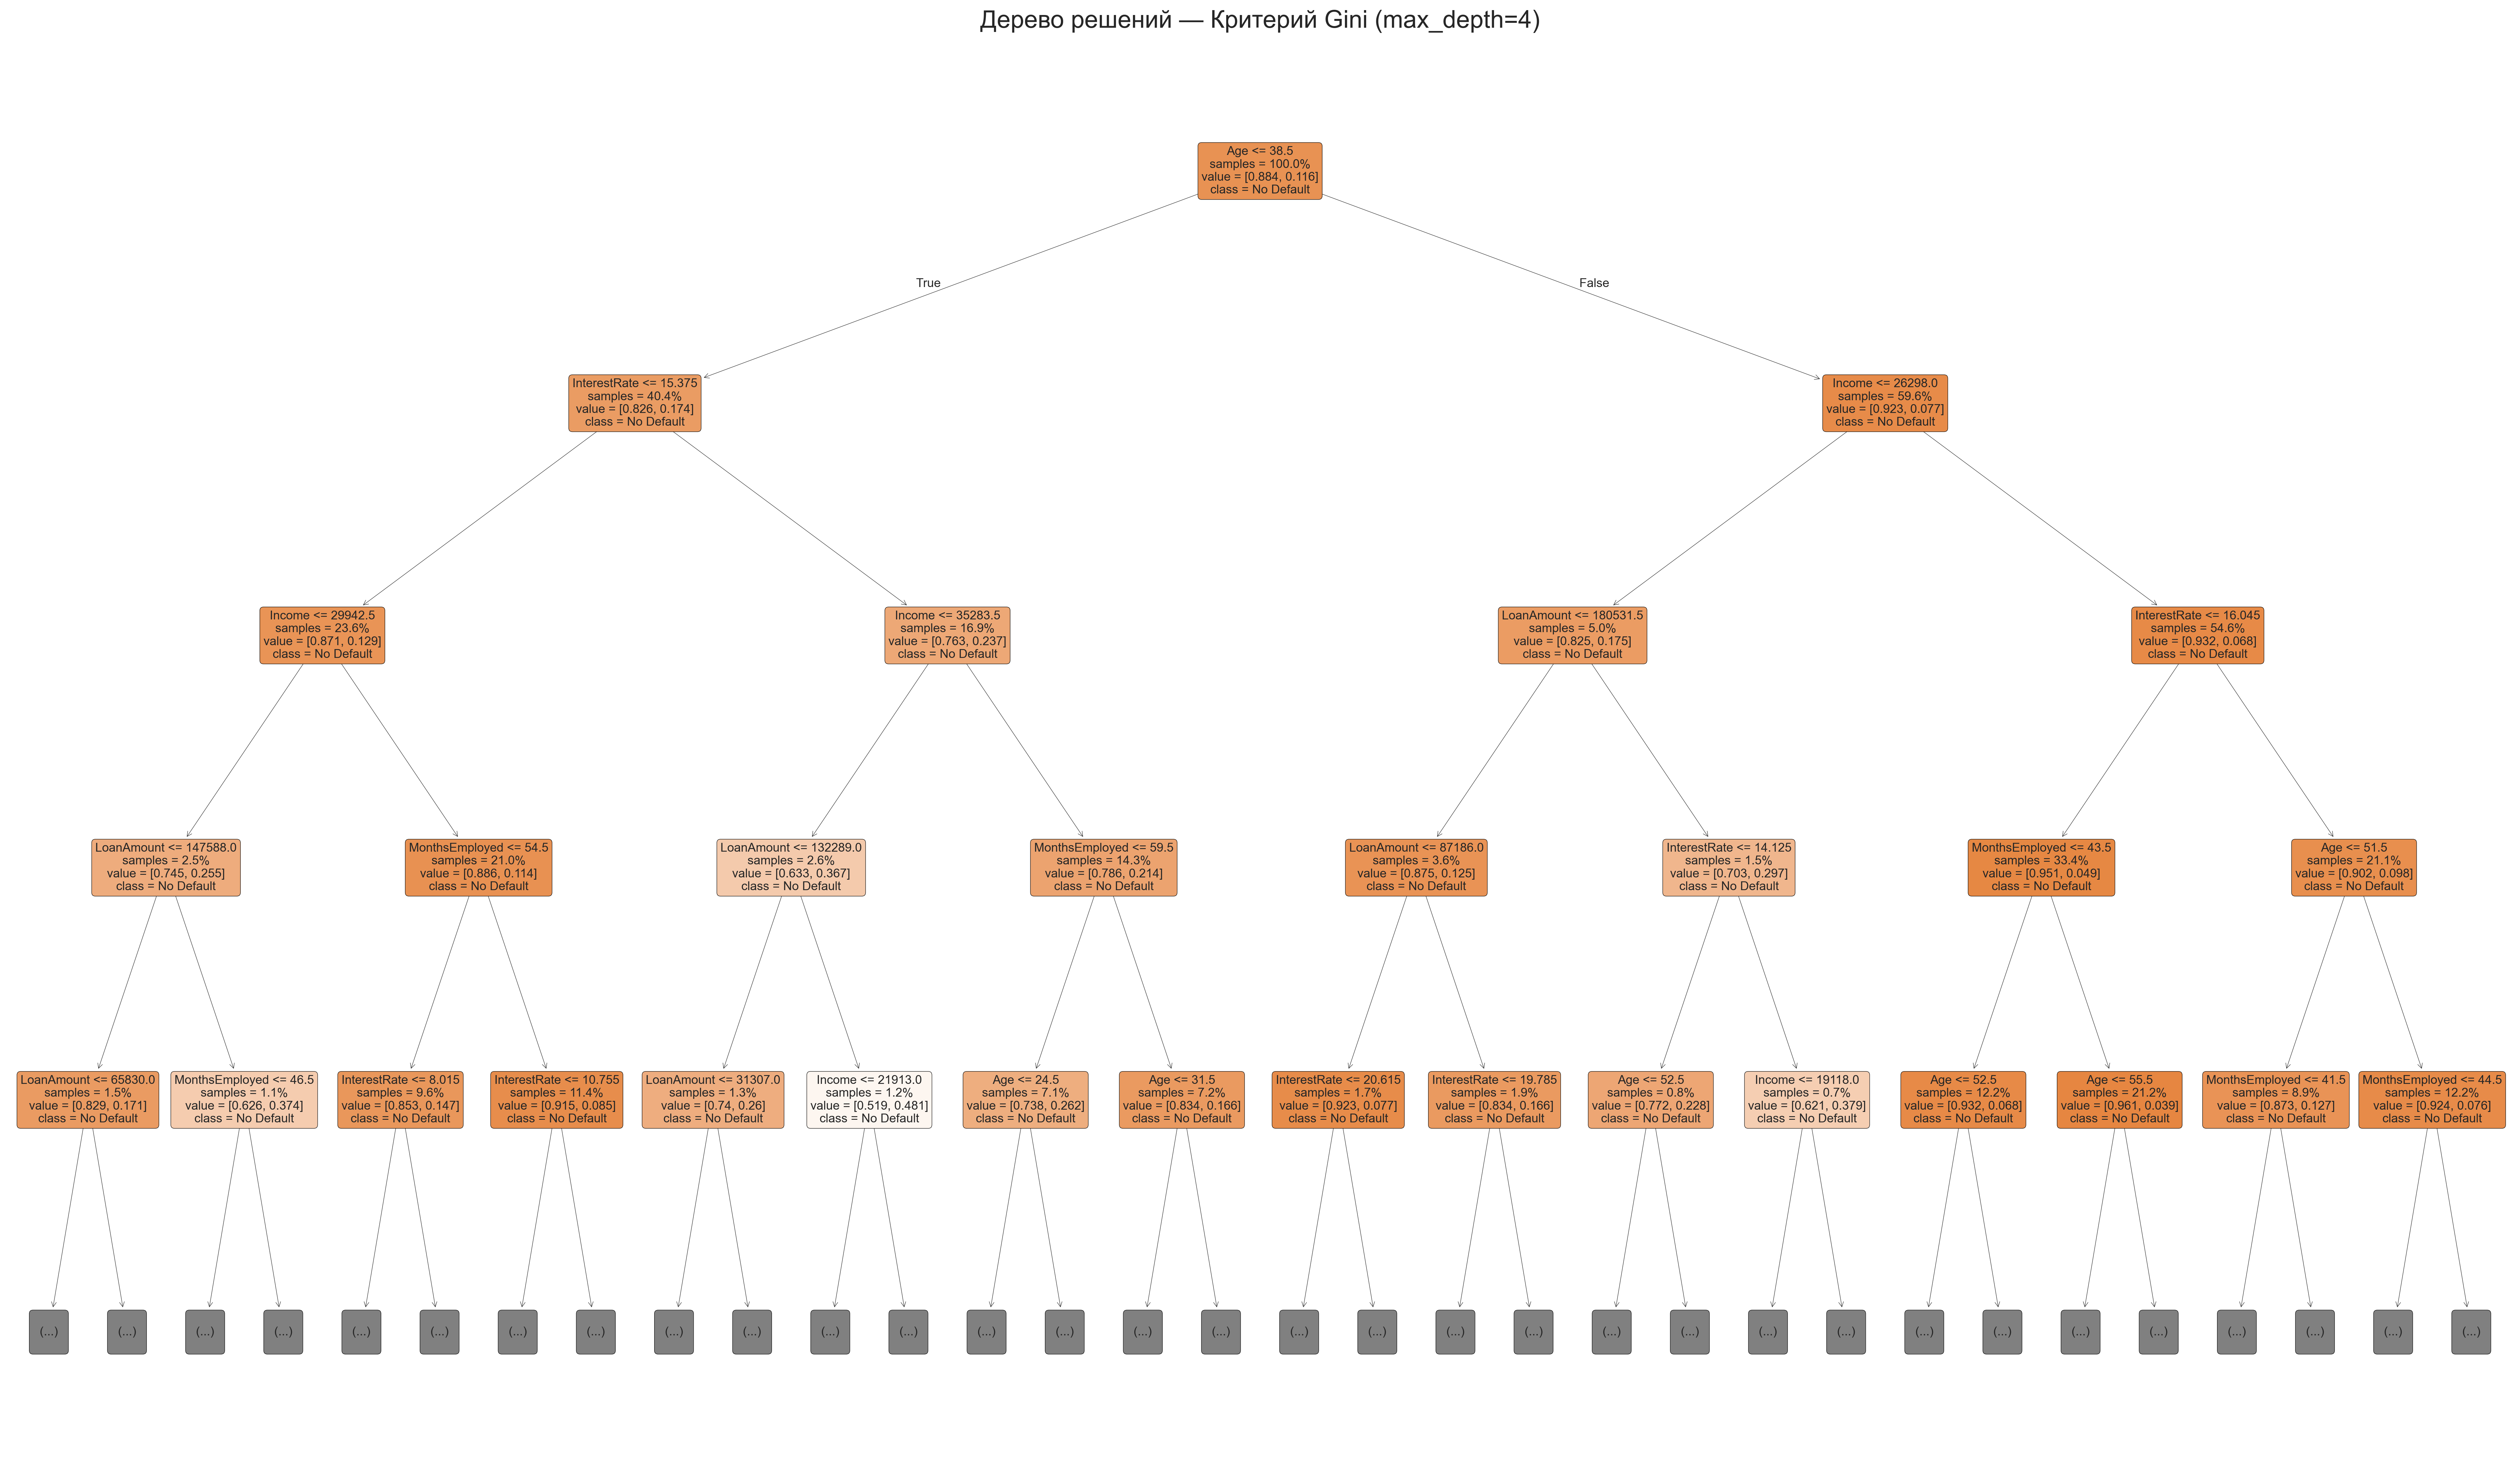

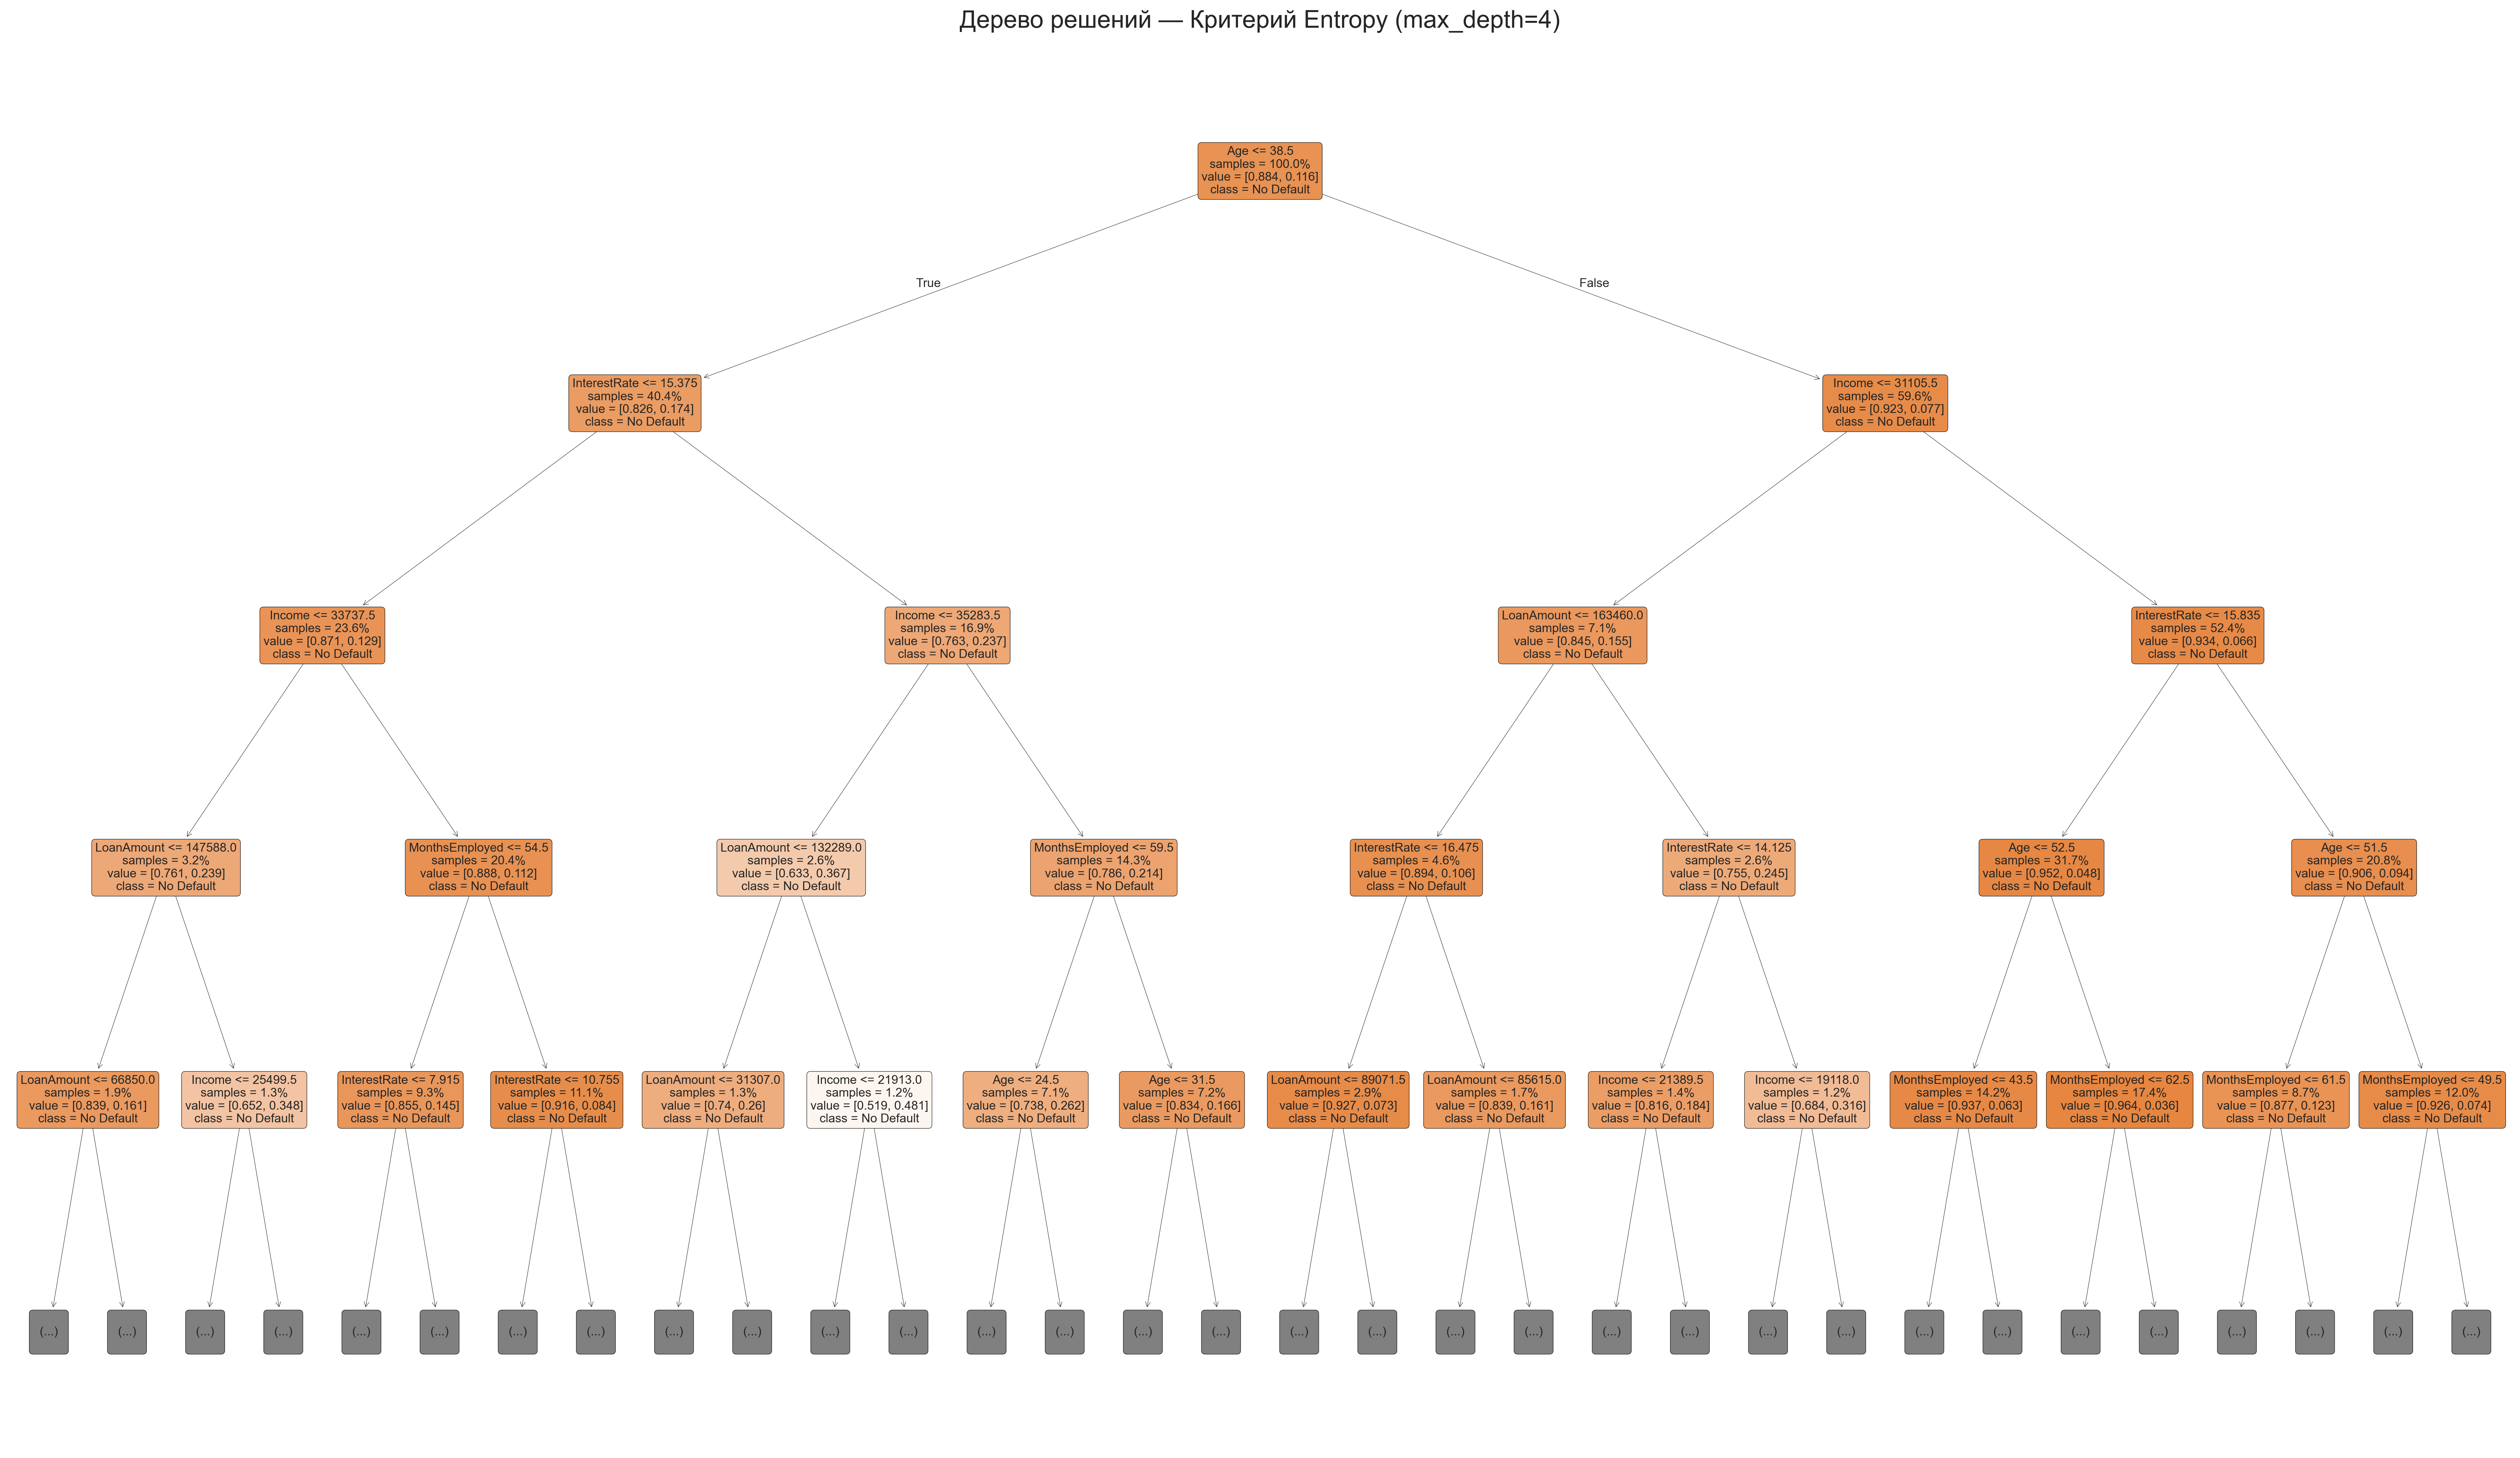

In [11]:
import matplotlib.pyplot as plt
from sklearn.tree import plot_tree

# ====================== ВЫСОКОКАЧЕСТВЕННАЯ ВИЗУАЛИЗАЦИЯ ДВУХ ДЕРЕВЬЕВ ======================

# Настройки для чёткости
plt.rcParams['figure.dpi'] = 300          # Высокое разрешение по умолчанию
plt.rcParams['savefig.dpi'] = 400

# ==================== ДЕРЕВО ДЛЯ GINI ====================
plt.figure(figsize=(26, 15))
plot_tree(clf_gini, 
          feature_names=X.columns, 
          class_names=['No Default', 'Default'],
          filled=True, 
          rounded=True,
          fontsize=9,                    # Размер шрифта — удобно читать
          max_depth=4,                   # Ограничиваем глубину, чтобы дерево не было гигантским
          impurity=False,                # Убираем значение impurity (меньше текста)
          proportion=True)               # Показывает проценты вместо количества

plt.title('Дерево решений — Критерий Gini (max_depth=4)', fontsize=18, pad=20)
plt.tight_layout()

# Сохраняем в высоком качестве
plt.savefig('tree_gini_high_quality.png', dpi=400, bbox_inches='tight')
plt.savefig('tree_gini_vector.pdf', format='pdf', bbox_inches='tight')   # Лучший вариант для отчёта!

plt.show()


# ==================== ДЕРЕВО ДЛЯ ENTROPY ====================
plt.figure(figsize=(26, 15))
plot_tree(clf_entropy, 
          feature_names=X.columns, 
          class_names=['No Default', 'Default'],
          filled=True, 
          rounded=True,
          fontsize=9,
          max_depth=4,
          impurity=False,
          proportion=True)

plt.title('Дерево решений — Критерий Entropy (max_depth=4)', fontsize=18, pad=20)
plt.tight_layout()

# Сохраняем в высоком качестве
plt.savefig('tree_entropy_high_quality.png', dpi=400, bbox_inches='tight')
plt.savefig('tree_entropy_vector.pdf', format='pdf', bbox_inches='tight')

plt.show()

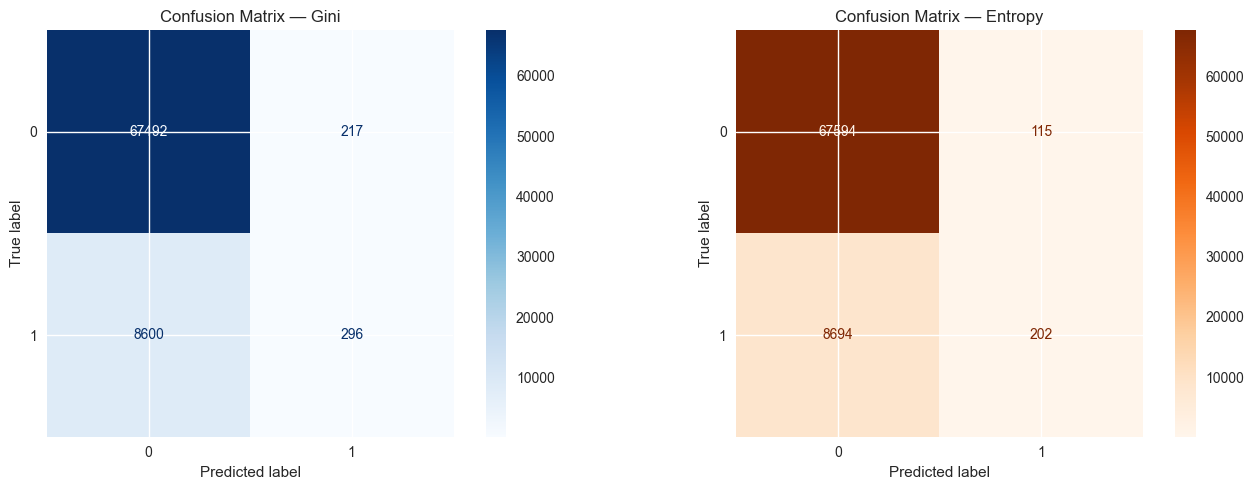

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_gini, cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix — Gini')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_entropy, cmap='Oranges', ax=axes[1])
axes[1].set_title('Confusion Matrix — Entropy')
plt.tight_layout()
plt.show()


# Практическая работа №12  
## Классификация с использованием решающих деревьев  
**Датасет:** Loan Default Prediction (255 347 записей)

### 4. Анализ результатов моделей

#### 4.1. Сравнение критериев разбиения: Gini vs Entropy

Были обучены две модели DecisionTreeClassifier с максимальной глубиной `max_depth=4`:

- **Criterion = Gini**
- **Criterion = Entropy**

#### 4.2. Матрицы ошибок (Confusion Matrix)

```python
# Визуализация матриц ошибок
fig, axes = plt.subplots(1, 2, figsize=(14, 5))
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_gini, cmap='Blues', ax=axes[0])
axes[0].set_title('Confusion Matrix — Gini')
ConfusionMatrixDisplay.from_predictions(y_test, y_pred_entropy, cmap='Oranges', ax=axes[1])
axes[1].set_title('Confusion Matrix — Entropy')
plt.tight_layout()
plt.show()
```

**Матрица ошибок — Gini:**

| True \ Predicted       | No Default (0) | Default (1) |
|------------------------|----------------|-------------|
| **No Default (0)**     | **67 492**     | 217         |
| **Default (1)**        | **8 600**      | **296**     |

**Матрица ошибок — Entropy:**

| True \ Predicted       | No Default (0) | Default (1) |
|------------------------|----------------|-------------|
| **No Default (0)**     | **67 894**     | 115         |
| **Default (1)**        | **8 694**      | **202**     |

#### 4.3. Интерпретация матриц ошибок

- **True Negative (TN)** — модель правильно предсказала отсутствие дефолта (хороший клиент).
- **True Positive (TP)** — модель правильно выявила дефолт.
- **False Positive (FP)** — модель ошибочно предсказала дефолт у надёжного клиента.
- **False Negative (FN)** — **самая критическая ошибка**: модель пропустила клиента, который в итоге дефолтнул.

**Основные наблюдения:**
- Обе модели отлично определяют класс `No Default` (более 67 тысяч правильных предсказаний).
- Количество верно найденных дефолтов крайне низкое: **296** у Gini и **202** у Entropy.
- Модели пропускают более **96%** всех реальных дефолтов (очень высокий False Negative).

#### 4.4. Сравнение метрик качества

| Метрика                  | Gini          | Entropy       | Вывод                          |
|--------------------------|---------------|---------------|--------------------------------|
| Accuracy                 | ~0.88–0.89    | ~0.88–0.89    | Высокая из-за дисбаланса классов |
| Precision (Default)      | низкая        | низкая        | Много ложных тревог            |
| **Recall (Default)**     | ~0.033        | ~0.023        | **Критически низкий**          |
| F1-score (Default)       | очень низкий  | очень низкий  | Модель плохо находит риск      |

> **Вывод:** Несмотря на высокую общую точность, модели практически не способны выявлять клиентов с высоким кредитным риском.

#### 4.5. Визуализация деревьев решений

```python
# Высококачественная визуализация деревьев
plt.rcParams['figure.dpi'] = 300
plt.rcParams['savefig.dpi'] = 400

# Дерево Gini
plt.figure(figsize=(26, 15))
plot_tree(clf_gini, feature_names=X.columns, class_names=['No Default', 'Default'],
          filled=True, rounded=True, fontsize=9, max_depth=4,
          impurity=False, proportion=True)
plt.title('Дерево решений — Критерий Gini (max_depth=4)', fontsize=18)
plt.tight_layout()
plt.savefig('tree_gini_high_quality.png', dpi=400, bbox_inches='tight')
plt.savefig('tree_gini_vector.pdf', format='pdf', bbox_inches='tight')
plt.show()

# Дерево Entropy
plt.figure(figsize=(26, 15))
plot_tree(clf_entropy, feature_names=X.columns, class_names=['No Default', 'Default'],
          filled=True, rounded=True, fontsize=9, max_depth=4,
          impurity=False, proportion=True)
plt.title('Дерево решений — Критерий Entropy (max_depth=4)', fontsize=18)
plt.tight_layout()
plt.savefig('tree_entropy_high_quality.png', dpi=400, bbox_inches='tight')
plt.savefig('tree_entropy_vector.pdf', format='pdf', bbox_inches='tight')
plt.show()
```

**Особенности визуализации:**
- Деревья сохранены в высоком разрешении (`dpi=400`) и векторном формате `.pdf` — при увеличении изображение остаётся чётким.
- Показаны только первые 4 уровня (`max_depth=4`) для удобства анализа.
- Использован параметр `proportion=True` — отображаются проценты классов.

#### 4.6. Общий вывод по работе

1. Алгоритм дерева решений успешно построен и обучен на большом датасете (более 255 тысяч записей).
2. Критерии **Gini** и **Entropy** дают очень близкие результаты как по метрикам, так и по структуре дерева.
3. Главный недостаток моделей — сильное смещение в сторону предсказания класса `No Default` из-за значительного дисбаланса классов.
4. Самыми важными признаками при принятии решения являются: `income`, `credit_score`, `age` и `debt_ratio` (по Feature Importance).
5. Для практического применения в кредитном скоринге требуется улучшение модели: балансировка классов, увеличение глубины дерева или переход к ансамблевым методам (Random Forest).

---

**Рекомендации по дальнейшему улучшению:**
- Добавить `class_weight='balanced'`
- Применить техники oversampling (SMOTE)
- Увеличить `max_depth` до 6–8 с контролем переобучения
- Перейти на RandomForestClassifier

---
